In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform, randint

In [2]:
# Fixed seed so results are reproducible
SEED = 42
np.random.seed(SEED)

In [3]:
# as_frame=True returns a pandas DataFrame directly
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDtypes:\n", df.dtypes)

# Transposed summary statistics for easy reading
df.describe().T

Missing values:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0

Dtypes:
 MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


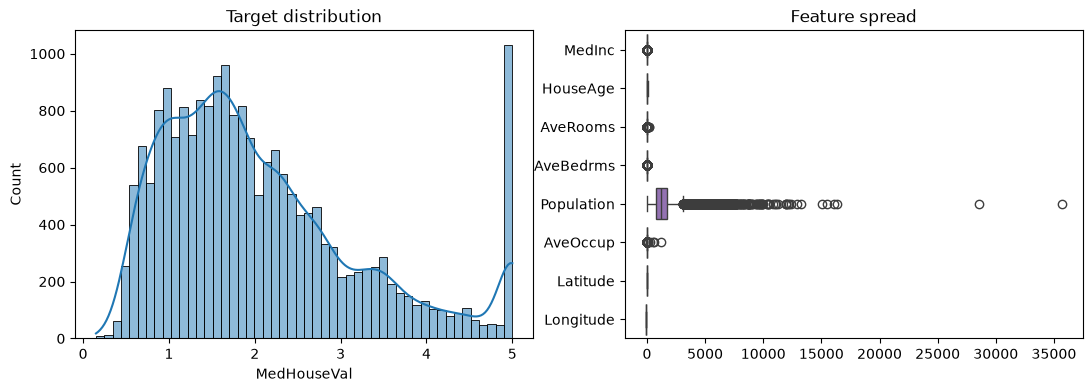

Rows at target cap (5.0): 992


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Target distribution
sns.histplot(df["MedHouseVal"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Target distribution")

# Spread of each feature (to spot outliers)
sns.boxplot(data=df.drop(columns="MedHouseVal"), orient="h", ax=ax[1])
ax[1].set_title("Feature spread")
plt.show()

# The target is capped at 5.0, so count how many rows sit at the cap
print("Rows at target cap (5.0):", (df["MedHouseVal"] >= 5.0).sum())

In [6]:
def add_features(X):
    """Create new ratio features from existing columns.
    Uses only values from the same row, so it is safe from data leakage."""
    X = X.copy()
    X["BedroomRatio"] = X["AveBedrms"] / X["AveRooms"]      # share of bedrooms among rooms
    X["RoomsPerPerson"] = X["AveRooms"] / X["AveOccup"]     # rooms available per occupant
    return X

In [7]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(X_train.shape, X_test.shape)


(16512, 8) (4128, 8)


In [8]:
def evaluate(model, X_te, y_te, name="Model"):
    """Print RMSE, MAE and R2 for a fitted model and return its predictions."""
    pred = model.predict(X_te)
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    mae = mean_absolute_error(y_te, pred)
    r2 = r2_score(y_te, pred)
    print(f"{name:<28} RMSE: {rmse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}")
    return pred

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    # Predicts the mean every time: the minimum score any real model must beat
    "Dummy (mean)": DummyRegressor(strategy="mean"),

    # Linear model needs scaling, so the scaler sits inside the pipeline
    "Linear Regression": Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    # Classic gradient boosting (slow on large data)
    "GradientBoosting (classic)": Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("model", GradientBoostingRegressor(random_state=SEED))
    ]),

    # Histogram-based gradient boosting (fast, industry favourite)
    "HistGradientBoosting": Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("model", HistGradientBoostingRegressor(random_state=SEED))
    ]),
}

for name, mdl in candidates.items():
    scores = -cross_val_score(mdl, X_train, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    print(f"{name:<28} CV RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

Dummy (mean)                 CV RMSE: 1.1562 (+/- 0.0122)
Linear Regression            CV RMSE: 0.6817 (+/- 0.0216)
GradientBoosting (classic)   CV RMSE: 0.5296 (+/- 0.0128)
HistGradientBoosting         CV RMSE: 0.4691 (+/- 0.0109)


In [11]:
pipe = Pipeline([
    ("fe", FunctionTransformer(add_features)),
    ("model", HistGradientBoostingRegressor(
        early_stopping=True,        # stop adding trees when validation score stops improving
        validation_fraction=0.1,    # 10% of training data held out internally for early stopping
        n_iter_no_change=20,        # patience: stop after 20 rounds without improvement
        random_state=SEED
    ))
    ])	

In [12]:
# "model__" prefix is required because the estimator lives inside a Pipeline step named "model"
param_dist = {
    "model__learning_rate": loguniform(0.01, 0.3),   # step size of each tree
    "model__max_iter": randint(300, 1500),           # max number of trees
    "model__max_leaf_nodes": randint(15, 80),        # complexity of each tree
    "model__max_depth": [None, 4, 6, 8, 10],         # depth limit (None = no limit)
    "model__min_samples_leaf": randint(10, 100),     # minimum samples per leaf (prevents overfitting)
    "model__l2_regularization": loguniform(1e-3, 10),# L2 penalty on leaf values
    "model__max_bins": [127, 255],                   # number of histogram bins per feature
}

In [13]:
search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=40,                                  # number of random combinations to try
    scoring="neg_root_mean_squared_error",      # sklearn maximizes, so RMSE is negated
    cv=cv,
    refit=True,                                 # retrain best model on full training data
    verbose=2,
    random_state=SEED,
    n_jobs=-1,                                  # use all CPU cores
    return_train_score=True                     # needed for the overfitting check later
)

In [14]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__l2_regularization': <scipy.stats....0018728398F90>, 'model__learning_rate': <scipy.stats....001872CD4A8D0>, 'model__max_bins': [127, 255], 'model__max_depth': [None, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the tr

In [15]:
print("Best Params:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

best_idx = search.best_index_
cv_rmse = -search.cv_results_["mean_test_score"][best_idx]
train_rmse = -search.cv_results_["mean_train_score"][best_idx]
print(f"\nCV RMSE (validation): {cv_rmse:.4f}")
print(f"CV RMSE (train)     : {train_rmse:.4f}")

# A very large gap means the model is overfitting
print(f"Gap                 : {cv_rmse - train_rmse:.4f}")

Best Params:
  model__l2_regularization: 0.47419068544776444
  model__learning_rate: 0.072068345324487
  model__max_bins: 255
  model__max_depth: None
  model__max_iter: 398
  model__max_leaf_nodes: 39
  model__min_samples_leaf: 27

CV RMSE (validation): 0.4573
CV RMSE (train)     : 0.3218
Gap                 : 0.1354


In [16]:
res = pd.DataFrame(search.cv_results_)
cols = ["mean_test_score", "std_test_score", "mean_fit_time"] + \
       [c for c in res.columns if c.startswith("param_")]

# Higher (less negative) score = better
res.sort_values("mean_test_score", ascending=False)[cols].head(5)

,mean_test_score,std_test_score,mean_fit_time,param_model__l2_regularization,param_model__learning_rate,param_model__max_bins,param_model__max_depth,param_model__max_iter,param_model__max_leaf_nodes,param_model__min_samples_leaf
33,-0.457259,0.009604,3.518636,0.474191,0.072068,255,None,398,39,27
29,-0.457529,0.009542,4.924997,0.038930,0.058181,255,None,772,64,32
36,-0.459349,0.009447,5.178285,0.147966,0.056439,255,10,862,68,17
25,-0.459484,0.010127,4.826969,0.132965,0.045860,255,8,502,70,26
35,-0.459546,0.011050,4.310118,0.001181,0.053646,255,8,1458,31,42
